# L4 · Savo GPT: mokymas, paieška ir UI

Skaitykite assignment.md. Pasirinkite vieną temą. Kodą ir prognozes pildykite patys; pateiktas karkasas tyčia neužbaigtas.


## Prieš pradėdami

Atverkite **assignment.md**: ten rasite darbo eigą, konkretų klausimo–atsakymo pavyzdį, ką gaunate ir ką įgyvendinate patys bei pateikimo sąrašą. Detalūs duomenų ir metrikų apibrėžimai – **TECHNICAL_DETAILS.md**. Rezultatų ruošinys – **EXPERIMENT_RESULTS.csv**.

Vieną temą pasirinkite žemiau per TOPIC. Pirmiausia užbaikite student_model.py ir student_search.py TODO; iki tol NotImplementedError numatytas. UI ir trijų sąlygų eksperimento kodą rašote patys. Modelis mokomas nuo atsitiktinių svorių.

In [1]:
from pathlib import Path
import sys,json,subprocess
ROOT=Path.cwd()
sys.path.insert(0,str(ROOT))
TOPIC='research'
LANG='LT'
DATA=ROOT/'data'/TOPIC
OUT=ROOT/'outputs'/(TOPIC+'_'+LANG)
print(sys.executable)
assert (DATA/'documents.jsonl').exists(), 'Open the extracted folder in VS Code.'

/home/claude/venv/bin/python


## 1. Patikrinkite duomenis ir atsakykite patys

In [2]:
from core import load_rows
documents=load_rows(DATA/'documents.jsonl')
train_rows=load_rows(DATA/'train.jsonl')
valid_rows=load_rows(DATA/'validation.jsonl')
print(len(documents),len(train_rows),len(valid_rows))
for r in valid_rows[:2]:
    print(r['source']);print(r['question'][LANG])
MANUAL_ANSWERS=[
  dict(question=valid_rows[0]['question'][LANG],my_answer='unknown',evidence='kortelėje nėra lauko license_reported (yra year, month, references, type)'),
  dict(question=valid_rows[1]['question'][LANG],my_answer='unknown',evidence='kortelėje nėra lauko authors'),
]
for m,r in zip(MANUAL_ANSWERS,valid_rows):print(m['my_answer'],'| etalonas:',r['answer'])

500 2100 200
Reference metadata. Title : An Overview of Machine Learning ; year : 2023 ; month : 12 ; references : 0 ; type : book-chapter ;
Ar metaduomenyse nurodyta licencija?
Reference metadata. Title : An Overview of Machine Learning ; year : 2023 ; month : 12 ; references : 0 ; type : book-chapter ;
Kiek autorių nurodyta?
unknown | etalonas: unknown
unknown | etalonas: unknown


### 4 tokenų priežastinė kaukė (1 = galima matyti, 0 = paslėpta prieš softmax, −∞)
| pozicija \ mato | t1 | t2 | t3 | t4 |
|---|---|---|---|---|
| t1 | 1 | 0 | 0 | 0 |
| t2 | 1 | 1 | 0 | 0 |
| t3 | 1 | 1 | 1 | 0 |
| t4 | 1 | 1 | 1 | 1 |

Ateitis slepiama, nes mokant visa seka (kontekstas + **atsakymas**) paduodama vienu metu. Be kaukės pozicija prieš atsakymą „pamatytų“ teisingą kitą tokeną ir modelis išmoktų jį tiesiog nukopijuoti iš dešinės. Generuojant tų tokenų dar nėra, todėl modelis neveiktų. Kaukė dedama prieš softmax: −∞ → exp(−∞)=0, todėl eilutė vis tiek sumuojasi į 1, o gradientas į ateitį neteka.

## 2. Įgyvendinkite attention ir kosinusą atskiruose failuose

In [3]:
for script in ['verify_attention.py','verify_search.py']:
    subprocess.run([sys.executable,str(ROOT/script)],cwd=ROOT,check=True)

PASS: shape, future mask, gradient isolation, known value sum


PASS: cosine scores, ordering and zero-query safety


## 3. Prognozė prieš mokymą ir eksperimentą

In [4]:
PREDICTION='''Prieš mokymą: be šaltinio GPT beveik visada atsakys unknown arba dažniausią mokymo reikšmę (EM ~0-5%).
Su teisinga kortele: kategoriniai laukai (type, license_reported) beveik 100%, skaitiniai (references, month) blogiausiai,
nes kelių skaitmenų skaičius reikia nukopijuoti tokenas po tokeno. Paieška: dažniausiai teisinga, bet
pavadinimai labai panašūs („Machine Learning ...“), o identiškų pavadinimų LSA neatskirs.
Taisyklė (laukų skaitymas) su teisinga kortele turėtų būti ~100%, t. y. geresnė už GPT.'''
REPAIR_PLAN=(ROOT/'outputs/research_LT/PREDICTION.txt').read_text(encoding='utf-8')
print(REPAIR_PLAN)

Užrašyta 2026-11-25 prieš pataisymo bandymą (bazinis validavimas jau išmatuotas, testas NEPALIESTAS).
Trūkumas: su TEISINGA kortele GPT blogai kopijuoja kelių skaitmenų skaičius (references 12/24, month 14/21);
mokymo nuostolis ~0,000, validavimo ~0,37 -> modelis įsimena laukų vietas, o ne skaito pagal lauko pavadinimą.
Pakeitimas (tik vienas): mokymo kortelėms pridedamos 2 papildomos kopijos su sumaišyta laukų tvarka, visa kita tas pats.
Prognozė: correct_card atsakomų EM 84,2 % -> ~88–90 %; daugiausia pagerės references ir month; teisingas unknown liks ~100 %;
paieškos top-1 nepasikeis (94,0 %), nes paieška nekeičiama. Rizika: rezultatas gali nepasikeisti arba pablogėti, nes per tą patį
žingsnių skaičių kiekviena originali kortelė matoma rečiau. Triukšmo patikra: bazinis modelis su seed 7.



## 4. Mokykite savo modelį nuo nulio. Ankstyvas sustojimas leidžiamas; nelaukite dirbtinai.

In [5]:
from core import train,Config
from student_model import CausalAttention
cfg=Config(dim=96,heads=4) if TOPIC=='research' else Config()
RETRAIN=False
if RETRAIN or not (OUT/'best.pt').exists():
    training_report=train(DATA,OUT,LANG,minutes=30,max_steps=10000,cfg=cfg,attention=CausalAttention)
else:
    training_report=json.loads((OUT/'training.json').read_text(encoding='utf-8'))
print({k:training_report[k] for k in ['config','parameters','vocab','steps','wall_seconds','best_validation_em','python','torch','training_device','threads']})

{'config': {'dim': 96, 'heads': 4, 'blocks': 2, 'context': 128, 'batch': 32, 'lr': 0.002, 'seed': 42}, 'parameters': 338450, 'vocab': 914, 'steps': 7500, 'wall_seconds': 275.275920114, 'best_validation_em': 0.875, 'python': '3.13.18 (main, Oct 26 2026, 14:08:19) [Clang 23.1.3 ]', 'torch': '2.15.0+cu132', 'training_device': 'cpu', 'threads': 1}


## 5. Peržiūrėkite validavimo rezultatą ir nuostolio kreivę

atkurtas žingsnis: 5500


{'n': 200, 'answerable': 158, 'unanswerable': 42, 'em': 0.875, 'answerable_em': 0.8417721518987342, 'unanswerable_em': 1.0, 'false_abstention': 0.012658227848101266, 'unsupported': 0.0}
license_reported  etalonas=             unknown  GPT=               unknown  eos=True
authors           etalonas=             unknown  GPT=               unknown  eos=True
license_reported  etalonas=                 yes  GPT=                   yes  eos=True
type              etalonas= proceedings-article  GPT= proceedings - article  eos=True
license_reported  etalonas=                 yes  GPT=                   yes  eos=True
type              etalonas=             unknown  GPT=               unknown  eos=True
license_reported  etalonas=             unknown  GPT=               unknown  eos=True
year              etalonas=                2022  GPT=                  2022  eos=True


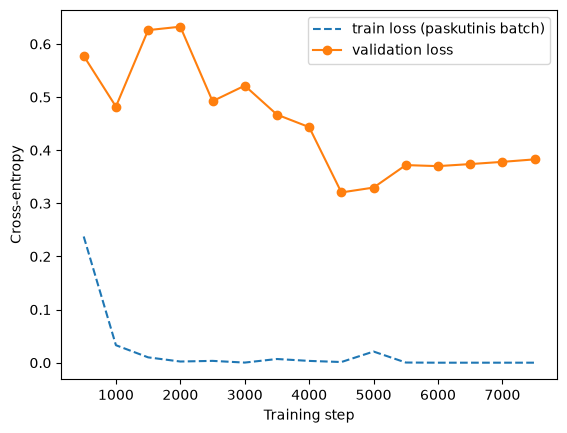

In [6]:
from core import restore,evaluate
import matplotlib.pyplot as plt
model,vocab,_=restore(OUT/'best.pt',attention=CausalAttention)
print('atkurtas žingsnis:',__import__('torch').load(OUT/'best.pt',weights_only=True)['step'])
validation,cases=evaluate(model,vocab,valid_rows,LANG)
print(validation)
for row in cases[:8]:print(f"{row['field']:17} etalonas={row['answer']:>20}  GPT={row['generated']:>22}  eos={row['eos']}")
history=json.loads((OUT/'history.json').read_text(encoding='utf-8'))
plt.plot([r['step'] for r in history],[r['train_loss'] for r in history],'--',label='train loss (paskutinis batch)')
plt.plot([r['step'] for r in history],[r['validation_loss'] for r in history],marker='o',label='validation loss')
plt.xlabel('Training step');plt.ylabel('Cross-entropy');plt.legend();plt.show()

## 6. Palyginkite tris sąlygas. Šį eksperimento kodą parašykite patys.

In [7]:
from retrieval import Retriever
from core import answer,metrics
import experiment
EXPERIMENT_RESULTS,EXP_CASES=experiment.run(OUT/'best.pt',DATA,'validation',LANG)
experiment.print_table(EXPERIMENT_RESULTS)
for k in ['correct_card','retrieved_card']:print(k,EXPERIMENT_RESULTS['results'][k]['per_field'])
r=EXPERIMENT_RESULTS['results']['retrieved_card']
print('Atsakomų klaidų su paieška:',r['answerable_errors_wrong_card'],'dėl blogos kortelės (paieškos klaida),',r['answerable_errors_right_card'],'su teisinga kortele (GPT klaida)')
print('Daugumos atsakymai (tik iš train):',EXPERIMENT_RESULTS['majority'])

condition                        retrieval_top1     answerable_EM      abstention       unsupported      incomplete      
no_source                        netaikoma          2/158 (1.3%)       34/42 (81.0%)    8/42 (19.0%)     0/200 (0.0%)    
correct_card                     netaikoma          133/158 (84.2%)    42/42 (100.0%)   0/42 (0.0%)      0/200 (0.0%)    
retrieved_card                   188/200 (94.0%)    132/158 (83.5%)    39/42 (92.9%)    3/42 (7.1%)      0/200 (0.0%)    
training_majority                netaikoma          48/158 (30.4%)     8/42 (19.0%)     34/42 (81.0%)    0/200 (0.0%)    
field_reading_rule               netaikoma          158/158 (100.0%)   42/42 (100.0%)   0/42 (0.0%)      0/200 (0.0%)    
field_reading_rule_on_retrieved  188/200 (94.0%)    156/158 (98.7%)    39/42 (92.9%)    3/42 (7.1%)      0/200 (0.0%)    
correct_card {'authors': {'answerable': '29/32', 'unanswerable': '4/4'}, 'license_reported': {'answerable': '27/27', 'unanswerable': '14/14'}, 'mo

## 7. Užbaikite UI ir patikrinkite savo pataisymą validavime

In [8]:
print('Run in a separate terminal:')
print(f'{sys.executable} app.py --topic {TOPIC} --checkpoint {OUT / "best.pt"}')
import csv
for row in csv.DictReader(open(OUT/'repair_before_after.csv',encoding='utf-8')):
    if row['condition']=='correct_card':print(row)
REPAIR_RESULT='''Pakeitimas: laukų tvarkos maišymas mokymo kortelėse (k=2 papildomos kopijos), visa kita ta pati.
Prognozė buvo +3..+6 p. EM. Rezultatas NEIGIAMAS: correct_card EM 133/158 -> 98/158 (84.2% -> 62.0%),
abstention 42/42 nepakito, paieška nepakito (188/200). Kategoriniai laukai liko 24/24 ir 27/27,
krito visi skaitiniai: year 27->18/30, authors 29->17/32, month 14->7/21, references 12->5/24.
Sėklos triukšmas (bazinis seed 7: 141/158) ~5 p., o pokytis -22 p., todėl tai ne atsitiktinumas.
Paaiškinimas: bazinis modelis naudojo FIKSUOTĄ laukų tvarką kaip nuorodą, kuris skaičius yra kuris
(year visada pirmas, references po authors). Maišant tvarką modelis turi susieti lauko pavadinimą su
po jo einančiais skaitmenimis vien turiniu; 2 blokų/96 dim. modeliui per ~5k žingsnių to neišmoko ir
ėmė spėlioti dažnas reikšmes (2020, 2022). Validavimo nuostolis kilo nuo 0.54 iki 1.27.
Sprendimas: pataisymo NEtaikau, galutiniam testui paliktas bazinis modelis.'''
REMAINING_ERROR='''Kelių skaitmenų references: modelis dažnai grąžina 0 (dažniausia mokymo reikšmė, 121/350) arba pirmą
skaitmenį (19 -> 1). Metai: mokyme tik 2020-2025, todėl 2019 nesugeneruojamas (žr. 8 skyrių, pakeistas faktas).
Paieška: visos 12/200 klaidų yra identiški pavadinimai (balas 1.000 abiem), juos atskirti gali tik DOI/autoriai.'''

Run in a separate terminal:
/home/claude/venv/bin/python app.py --topic research --checkpoint /home/claude/mat/Lab04_LT/outputs/research_LT/best.pt
{'run': 'baseline_seed42', 'condition': 'correct_card', 'em': '133/158', 'abstention': '42/42', 'unsupported': '0/42', 'incomplete': '0/200', 'em_authors': '29/32', 'em_license_reported': '27/27', 'em_month': '14/21', 'em_references': '12/24', 'em_type': '24/24', 'em_year': '27/30'}
{'run': 'baseline_seed7 (noise check)', 'condition': 'correct_card', 'em': '141/158', 'abstention': '41/42', 'unsupported': '1/42', 'incomplete': '0/200', 'em_authors': '30/32', 'em_license_reported': '27/27', 'em_month': '16/21', 'em_references': '16/24', 'em_type': '24/24', 'em_year': '28/30'}
{'run': 'repair_field_shuffle_seed42', 'condition': 'correct_card', 'em': '98/158', 'abstention': '42/42', 'unsupported': '0/42', 'incomplete': '0/200', 'em_authors': '17/32', 'em_license_reported': '27/27', 'em_month': '7/21', 'em_references': '5/24', 'em_type': '24/24'

## 8. Tik užfiksavę nustatymus vertinkite testą ir savo klausimus

In [9]:
SETTINGS_FROZEN=True
if SETTINGS_FROZEN:
    final=json.loads((OUT/'exp_test.json').read_text(encoding='utf-8'))
    experiment.print_table(final)
    (OUT/'final_metrics.json').write_text(json.dumps({k:{a:b for a,b in v.items() if a!='per_field'} for k,v in final['results'].items()},indent=2),encoding='utf-8')
pq=json.loads((OUT/'personal_questions.json').read_text(encoding='utf-8'))
PERSONAL_QUESTIONS=pq['questions']
for x in PERSONAL_QUESTIONS:print(f"{x['kind']:8} paieška={'OK ' if x['retrieval_ok'] else 'BLOGA'} laukta={x['expected']:>20} GPT={x['generated']:>22} {'✓' if x['correct'] else '✗'} {x['question']} [{x['source_url']}]")
for e in pq['edited_facts']:print('PAKEISTAS FAKTAS',e)
CONCLUSION='''GPT su teisinga kortele: val 84.2% / test 92.0% EM atsakomiems, 100% / 96% teisingų unknown.
Be šaltinio GPT beveik nieko nežino (1-2 EM) -> jis atsakymus skaito iš konteksto, o ne iš atminties.
Paieškos top-1 94% / 96%; visos klaidos - identiški pavadinimai. Taisyklė (laukų skaitymas) 100% - geresnė už GPT,
nes formatas visiškai struktūruotas; GPT tik iš dalies kopijuoja ir realiai rinkosi iš mokyme matytų reikšmių
(2019 metų nesugeneravo). Laukų maišymo pataisymas pablogino (-22 p.), todėl neįtrauktas.
Savo klausimai: 4/10; šabloniniai 2/6, laisvi 2/4.'''
print(CONCLUSION)

condition                        retrieval_top1     answerable_EM      abstention       unsupported      incomplete      
no_source                        netaikoma          1/75 (1.3%)        18/25 (72.0%)    7/25 (28.0%)     0/100 (0.0%)    
correct_card                     netaikoma          69/75 (92.0%)      24/25 (96.0%)    1/25 (4.0%)      0/100 (0.0%)    
retrieved_card                   96/100 (96.0%)     68/75 (90.7%)      24/25 (96.0%)    1/25 (4.0%)      0/100 (0.0%)    
training_majority                netaikoma          32/75 (42.7%)      7/25 (28.0%)     18/25 (72.0%)    0/100 (0.0%)    
field_reading_rule               netaikoma          75/75 (100.0%)     25/25 (100.0%)   0/25 (0.0%)      0/100 (0.0%)    
field_reading_rule_on_retrieved  96/100 (96.0%)     74/75 (98.7%)      25/25 (100.0%)   0/25 (0.0%)      0/100 (0.0%)    
template paieška=OK  laukta=                  40 GPT=                     0 ✗ Kiek literatūros nuorodų nurodyta? [https://doi.org/10.4018/978-1-79